<a href="https://colab.research.google.com/github/jyothirmaij/assesment_3_jyothirmai/blob/main/assesment3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [66]:
import pandas as pd
import numpy as np

train = pd.read_csv('/content/drive/MyDrive/DSA/cases study/assesment 3/train_LZdllcl.csv')
test = pd.read_csv('/content/drive/MyDrive/DSA/cases study/assesment 3/test_2umaH9m.csv')
sample_submission = pd.read_csv('/content/drive/MyDrive/DSA/cases study/assesment 3/sample_submission_M0L0uXE.csv')

In [67]:
train.shape

(54808, 14)

In [68]:
test.shape

(23490, 13)

In [69]:
sample_submission.shape

(23490, 2)

In [70]:
train.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73,0


In [71]:
test.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
0,8724,Technology,region_26,Bachelor's,m,sourcing,1,24,NaN,1,1,0,77
1,74430,HR,region_4,Bachelor's,f,other,1,31,3.0,5,0,0,51
2,72255,Sales & Marketing,region_13,Bachelor's,m,other,1,31,1.0,4,0,0,47
3,38562,Procurement,region_2,Bachelor's,f,other,3,31,2.0,9,0,0,65
4,64486,Finance,region_29,Bachelor's,m,sourcing,1,30,4.0,7,0,0,61


In [72]:
train.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
count,54808.000000,54808.000000,54808.000000,50684.000000,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000
mean,39195.830627,1.253011,34.803915,3.329256,5.865512,0.351974,0.023172,63.386750,0.085170
std,22586.581449,0.609264,7.660169,1.259993,4.265094,0.477590,0.150450,13.371559,0.279137
min,1.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000,0.000000
25%,19669.750000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000,0.000000
50%,39225.500000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000,0.000000
75%,58730.500000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,76.000000,0.000000
max,78298.000000,10.000000,60.000000,5.000000,37.000000,1.000000,1.000000,99.000000,1.000000


In [73]:
train.describe(include='object')

,department,region,education,gender,recruitment_channel
count,54808,54808,52399,54808,54808
unique,9,34,3,2,3
top,Sales & Marketing,region_2,Bachelor's,m,other
freq,16840,12343,36669,38496,30446


In [74]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  object 
 2   region                54808 non-null  object 
 3   education             52399 non-null  object 
 4   gender                54808 non-null  object 
 5   recruitment_channel   54808 non-null  object 
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  KPIs_met >80%         54808 non-null  int64  
 11  awards_won?           54808 non-null  int64  
 12  avg_training_score    54808 non-null  int64  
 13  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.9+ MB


In [75]:
train['is_promoted'].value_counts()

,count
is_promoted,
0,50140
1,4668


In [76]:
train['is_promoted'].value_counts()
#Your target is imbalanced

,count
is_promoted,
0,50140
1,4668


In [77]:
train.isnull().sum()

,0
employee_id,0
department,0
region,0
education,2409
gender,0
recruitment_channel,0
no_of_trainings,0
age,0
previous_year_rating,4124
length_of_service,0


In [78]:
train.duplicated().sum()

np.int64(0)

eda


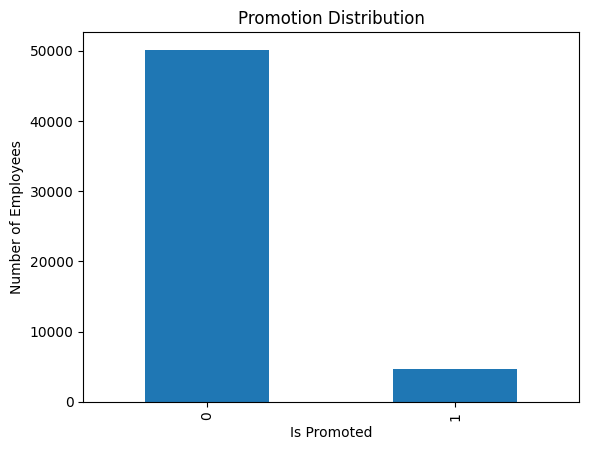

In [79]:
import matplotlib.pyplot as plt

train['is_promoted'].value_counts().plot(kind='bar')

plt.title('Promotion Distribution')
plt.xlabel('Is Promoted')
plt.ylabel('Number of Employees')
plt.show()

In [80]:
train.groupby('department')['is_promoted'].mean().sort_values(ascending=False)

,is_promoted
department,
Technology,0.107593
Procurement,0.096386
Analytics,0.095665
Operations,0.090148
Finance,0.081230
Sales & Marketing,0.072031
R&D,0.069069
HR,0.056245
Legal,0.051011


In [81]:
train.groupby('education')['is_promoted'].mean()

,is_promoted
education,
Bachelor's,0.082031
Below Secondary,0.083230
Master's & above,0.098559


In [82]:
train.groupby('gender')['is_promoted'].mean()

,is_promoted
gender,
f,0.089934
m,0.083151


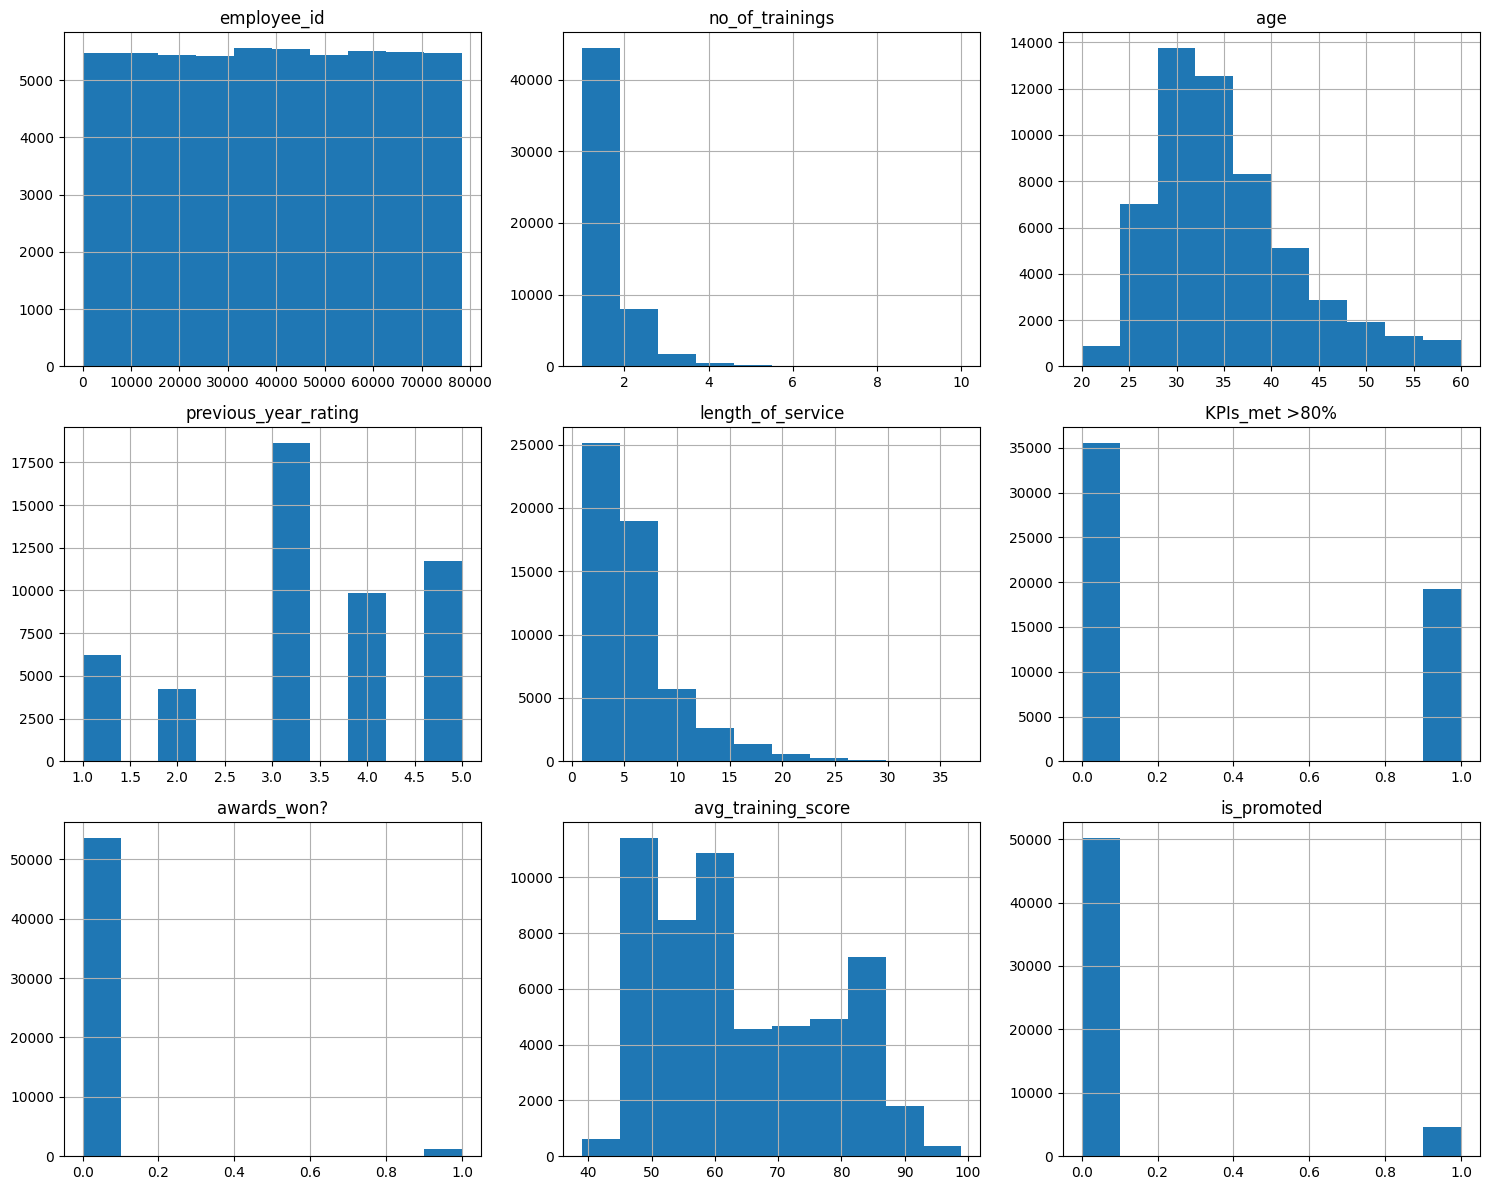

In [83]:
train.hist(figsize=(15,12))
plt.tight_layout()
plt.show()

In [84]:
train.groupby('gender')['is_promoted'].mean()

,is_promoted
gender,
f,0.089934
m,0.083151


In [85]:
train.groupby('is_promoted')['age'].mean()

,age
is_promoted,
0,34.844037
1,34.372965


In [86]:
train.groupby('is_promoted')['avg_training_score'].mean()

,avg_training_score
is_promoted,
0,62.647686
1,71.325193


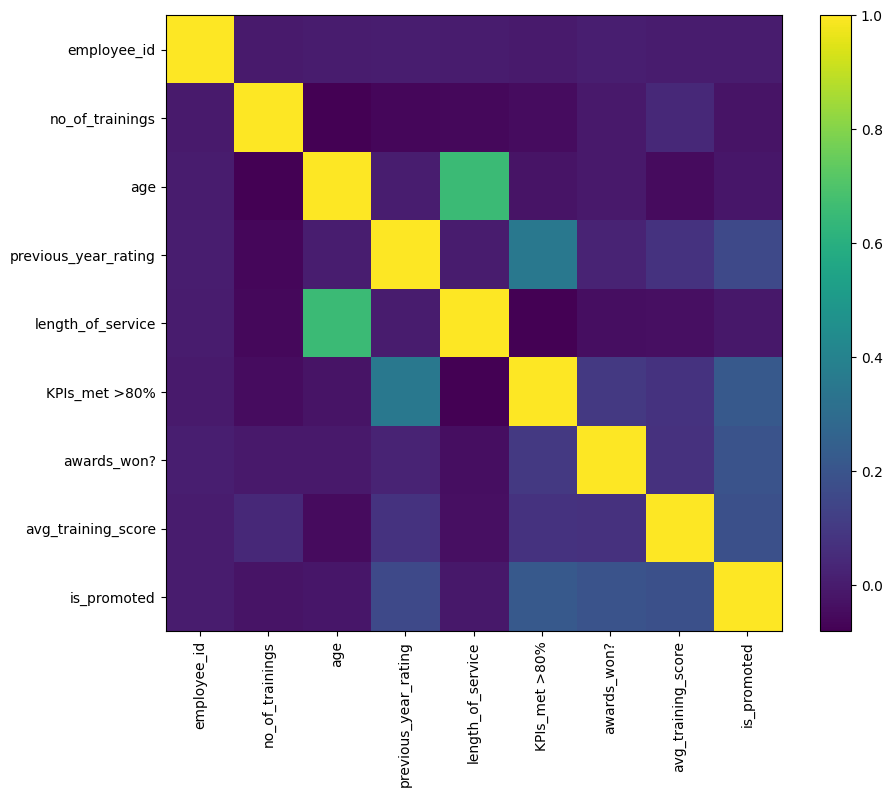

In [87]:
plt.figure(figsize=(10,8))

corr = train.select_dtypes(include=np.number).corr()

plt.imshow(corr)
plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.show()

Pre-processing


In [88]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [89]:
categorical_columns = [
    'department',
    'region',
    'education',
    'gender',
    'recruitment_channel'
]

numerical_columns = [
    'employee_id',
    'no_of_trainings',
    'age',
    'previous_year_rating',
    'length_of_service',
    'KPIs_met >80%',
    'awards_won?',
    'avg_training_score'
]

In [90]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [91]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

In [92]:
X = train.drop('is_promoted', axis=1)
y = train['is_promoted']

In [93]:
X.shape

(54808, 13)

In [94]:
y.shape

(54808,)

In [95]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

logistic regression


In [96]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

In [97]:
logistic_model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['employee_id',
                                                   'no_of_trainings', 'age',
                                                   'previous_year_rating',
                                                   'length_of_service',
                                                   'KPIs_met >80%',
                                                   'awards_won?',
                                                   'avg_training_score']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['department', 'region',
                                                   'education', 'gender',
                                                   'recruitment_channel'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [98]:
y_pred = logistic_model.predict(X_valid)

In [99]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_valid, y_pred))
print("Precision:", precision_score(y_valid, y_pred))
print("Recall:", recall_score(y_valid, y_pred))
print("F1:", f1_score(y_valid, y_pred))

print(classification_report(y_valid, y_pred))

Accuracy: 0.7448458310527276
Precision: 0.21900452488687783
Recall: 0.7773019271948608
F1: 0.34172746528594966
              precision    recall  f1-score   support

           0       0.97      0.74      0.84     10028
           1       0.22      0.78      0.34       934

    accuracy                           0.74     10962
   macro avg       0.60      0.76      0.59     10962
weighted avg       0.91      0.74      0.80     10962



In [100]:
confusion_matrix(y_valid, y_pred)

array([[7439, 2589],
       [ 208,  726]])

Random Forest

In [101]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced'
    ))
])

In [102]:
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['employee_id',
                                                   'no_of_trainings', 'age',
                                                   'previous_year_rating',
                                                   'length_of_service',
                                                   'KPIs_met >80%',
                                                   'awards_won?',
                                                   'avg_training_score']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['department', 'region',
                                                   'education', 'gender',
                                                   'recruitment_channel'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, random_state=42))])

In [103]:
rf_pred = rf_model.predict(X_valid)

In [104]:
print("Accuracy:", accuracy_score(y_valid, rf_pred))
print("Precision:", precision_score(y_valid, rf_pred))
print("Recall:", recall_score(y_valid, rf_pred))
print("F1:", f1_score(y_valid, rf_pred))

Accuracy: 0.9356869184455391
Precision: 0.9386973180076629
Recall: 0.2623126338329764
F1: 0.4100418410041841


Gradient Boosting



In [105]:
from sklearn.ensemble import GradientBoostingClassifier

In [106]:
gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [107]:
gb_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['employee_id',
                                                   'no_of_trainings', 'age',
                                                   'previous_year_rating',
                                                   'length_of_service',
                                                   'KPIs_met >80%',
                                                   'awards_won?',
                                                   'avg_training_score']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['department', 'region',
                                                   'education', 'gender',
                                                   'recruitment_channel'])])),
                ('model', GradientBoostingClassifier(random_state=42))])

In [108]:
gb_pred = gb_model.predict(X_valid)

In [109]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_valid, gb_pred))
print("Precision:", precision_score(y_valid, gb_pred))
print("Recall:", recall_score(y_valid, gb_pred))
print("F1:", f1_score(y_valid, gb_pred))

print("\nClassification Report:")
print(classification_report(y_valid, gb_pred))

Accuracy: 0.9376938514869549
Precision: 0.9845559845559846
Recall: 0.27301927194860814
F1: 0.42749371332774516

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97     10028
           1       0.98      0.27      0.43       934

    accuracy                           0.94     10962
   macro avg       0.96      0.64      0.70     10962
weighted avg       0.94      0.94      0.92     10962



decision tree

In [110]:
from sklearn.tree import DecisionTreeClassifier

In [111]:
dt_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ))
])

In [112]:
dt_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['employee_id',
                                                   'no_of_trainings', 'age',
                                                   'previous_year_rating',
                                                   'length_of_service',
                                                   'KPIs_met >80%',
                                                   'awards_won?',
                                                   'avg_training_score']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['department', 'region',
                                                   'education', 'gender',
                                                   'recruitment_channel'])])),
                ('model',
                 DecisionTreeClassifier(class_weight='balanced',
                                        random_state=42))])

In [113]:
dt_pred = dt_model.predict(X_valid)

In [114]:
print("Accuracy:", accuracy_score(y_valid, dt_pred))
print("Precision:", precision_score(y_valid, dt_pred))
print("Recall:", recall_score(y_valid, dt_pred))
print("F1:", f1_score(y_valid, dt_pred))

print("\nClassification Report:")
print(classification_report(y_valid, dt_pred))

Accuracy: 0.9004743659916074
Precision: 0.4201424211597152
Recall: 0.4421841541755889
F1: 0.43088158581116326

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95     10028
           1       0.42      0.44      0.43       934

    accuracy                           0.90     10962
   macro avg       0.68      0.69      0.69     10962
weighted avg       0.90      0.90      0.90     10962



In [115]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Gradient Boosting',
        'Decision Tree'
    ],
    'Accuracy': [
        accuracy_score(y_valid, y_pred),
        accuracy_score(y_valid, rf_pred),
        accuracy_score(y_valid, gb_pred),
        accuracy_score(y_valid, dt_pred)
    ],
    'F1': [
        f1_score(y_valid, y_pred),
        f1_score(y_valid, rf_pred),
        f1_score(y_valid, gb_pred),
        f1_score(y_valid, dt_pred)

    ]
})

results

,Model,Accuracy,F1
0,Logistic Regression,0.744846,0.341727
1,Random Forest,0.935687,0.410042
2,Gradient Boosting,0.937694,0.427494
3,Decision Tree,0.900474,0.430882


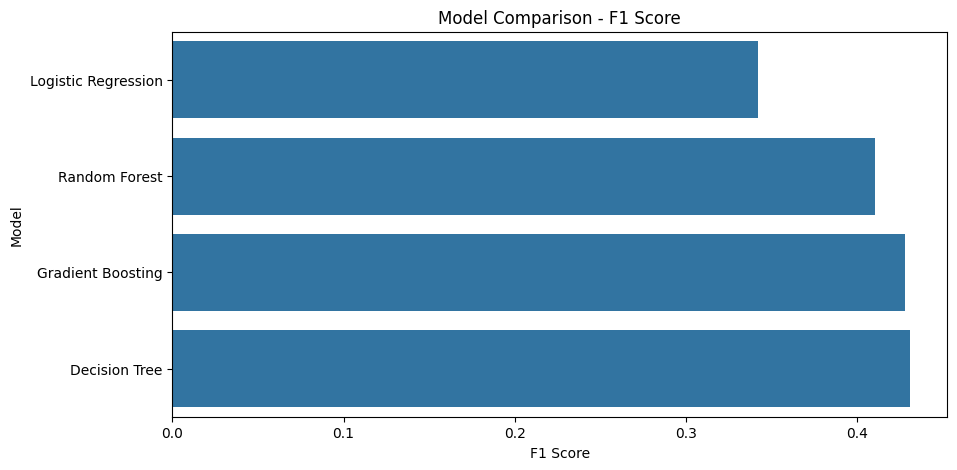

In [116]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='F1',
    y='Model'
)

plt.title('Model Comparison - F1 Score')
plt.xlabel('F1 Score')
plt.ylabel('Model')

plt.show()

Decision Tree Fine-Tuning

In [117]:
from sklearn.model_selection import GridSearchCV

In [118]:
param_grid_dt = {
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5, 10],
    'model__criterion': ['gini', 'entropy']
}

In [119]:
dt_grid = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid_dt,
    scoring='f1',
    cv=3,
    n_jobs=-1,
    verbose=1
)

In [120]:
dt_grid.fit(X_train, y_train)

Fitting 3 folds for each of 120 candidates, totalling 360 fits


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median'))]),
                                                                         ['employee_id',
                                                                          'no_of_trainings',
                                                                          'age',
                                                                          'previous_year_rating',
                                                                          'length_of_service',
                                                                          'KPIs_met '
                                                                          '>80%',
                                                                          'awards_won?',
                                                                          'avg_training_score']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(stra...
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['department',
                                                                          'region',
                                                                          'education',
                                                                          'gender',
                                                                          'recruitment_channel'])])),
                                       ('model',
                                        DecisionTreeClassifier(class_weight='balanced',
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__criterion': ['gini', 'entropy'],
                         'model__max_depth': [5, 10, 15, 20, None],
                         'model__min_samples_leaf': [1, 2, 5, 10],
                         'model__min_samples_split': [2, 5, 10]},
             scoring='f1', verbose=1)

In [121]:
print("Best Parameters:")
print(dt_grid.best_params_)

Best Parameters:
{'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}


In [122]:
print("Best CV F1:")
print(dt_grid.best_score_)

Best CV F1:
0.42704817343674906


In [123]:
best_dt = dt_grid.best_estimator_

In [124]:
dt_tuned_pred = best_dt.predict(X_valid)

In [125]:
print("Accuracy:", accuracy_score(y_valid, dt_tuned_pred))
print("Precision:", precision_score(y_valid, dt_tuned_pred))
print("Recall:", recall_score(y_valid, dt_tuned_pred))
print("F1:", f1_score(y_valid, dt_tuned_pred))

Accuracy: 0.8990147783251231
Precision: 0.41560975609756096
Recall: 0.45610278372591007
F1: 0.4349157733537519


In [126]:
print(classification_report(y_valid, dt_tuned_pred))

              precision    recall  f1-score   support

           0       0.95      0.94      0.94     10028
           1       0.42      0.46      0.43       934

    accuracy                           0.90     10962
   macro avg       0.68      0.70      0.69     10962
weighted avg       0.90      0.90      0.90     10962



Fine-tune Gradient Boosting

In [131]:
param_grid_gb = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.1],
    'model__max_depth': [2, 3]
}

In [132]:
gb_grid = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid_gb,
    scoring='f1',
    cv=3,
    n_jobs=-1,
    verbose=1
)

In [133]:
gb_grid.fit(X_train, y_train)

Fitting 3 folds for each of 4 candidates, totalling 12 fits


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median'))]),
                                                                         ['employee_id',
                                                                          'no_of_trainings',
                                                                          'age',
                                                                          'previous_year_rating',
                                                                          'length_of_service',
                                                                          'KPIs_met '
                                                                          '>80%',
                                                                          'awards_won?',
                                                                          'avg_training_score']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['department',
                                                                          'region',
                                                                          'education',
                                                                          'gender',
                                                                          'recruitment_channel'])])),
                                       ('model',
                                        GradientBoostingClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__learning_rate': [0.1],
                         'model__max_depth': [2, 3],
                         'model__n_estimators': [100, 200]},
             scoring='f1', verbose=1)

In [134]:
print("Best Parameters:")
print(gb_grid.best_params_)

print("\nBest CV F1:")
print(gb_grid.best_score_)

Best Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}

Best CV F1:
0.4733658358994007


In [135]:
best_gb = gb_grid.best_estimator_

gb_tuned_pred = best_gb.predict(X_valid)

print("Accuracy:", accuracy_score(y_valid, gb_tuned_pred))
print("Precision:", precision_score(y_valid, gb_tuned_pred))
print("Recall:", recall_score(y_valid, gb_tuned_pred))
print("F1:", f1_score(y_valid, gb_tuned_pred))

Accuracy: 0.9404305783616128
Precision: 0.9606557377049181
Recall: 0.31370449678800855
F1: 0.47296206618240516


In [136]:
print(classification_report(y_valid, gb_tuned_pred))

              precision    recall  f1-score   support

           0       0.94      1.00      0.97     10028
           1       0.96      0.31      0.47       934

    accuracy                           0.94     10962
   macro avg       0.95      0.66      0.72     10962
weighted avg       0.94      0.94      0.93     10962



In [137]:
print("Accuracy:", accuracy_score(y_valid, gb_tuned_pred))
print("Precision:", precision_score(y_valid, gb_tuned_pred))
print("Recall:", recall_score(y_valid, gb_tuned_pred))
print("F1:", f1_score(y_valid, gb_tuned_pred))

print("\nBest Parameters:")
print(gb_grid.best_params_)

print("\nBest CV F1:")
print(gb_grid.best_score_)


Accuracy: 0.9404305783616128
Precision: 0.9606557377049181
Recall: 0.31370449678800855
F1: 0.47296206618240516

Best Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}

Best CV F1:
0.4733658358994007


In [138]:
final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [139]:
final_model.fit(X, y)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['employee_id',
                                                   'no_of_trainings', 'age',
                                                   'previous_year_rating',
                                                   'length_of_service',
                                                   'KPIs_met >80%',
                                                   'awards_won?',
                                                   'avg_training_score']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['department', 'region',
                                                   'education', 'gender',
                                                   'recruitment_channel'])])),
                ('model',
                 GradientBoostingClassifier(n_estimators=200,
                                            random_state=42))])

In [140]:
test_predictions = final_model.predict(test)

In [141]:
print(len(test_predictions))

23490


In [142]:
print(pd.Series(test_predictions).value_counts())

0    22848
1      642
Name: count, dtype: int64


In [144]:
submission = sample_submission.copy()

submission['is_promoted'] = test_predictions

In [145]:
submission.head()

,employee_id,is_promoted
0,8724,0
1,74430,0
2,72255,0
3,38562,0
4,64486,0


In [146]:
submission.shape

(23490, 2)

In [147]:
print(submission.columns)
print(submission.isnull().sum())
print(submission['is_promoted'].value_counts())

Index(['employee_id', 'is_promoted'], dtype='object')
employee_id    0
is_promoted    0
dtype: int64
is_promoted
0    22848
1      642
Name: count, dtype: int64


In [148]:
submission.to_csv(
    '/content/drive/MyDrive/DSA/cases study/assesment 3/final_submission.csv',
    index=False
)

In [150]:
final_check = pd.read_csv('/content/drive/MyDrive/DSA/cases study/assesment 3/final_submission.csv')

print(final_check.shape)
print(final_check.head())

(23490, 2)
   employee_id  is_promoted
0         8724            0
1        74430            0
2        72255            0
3        38562            0
4        64486            0


sdfsfsf

In [151]:
y_valid_proba = best_gb.predict_proba(X_valid)[:, 1]

thresholds = np.arange(0.10, 0.61, 0.01)

f1_scores = []

for threshold in thresholds:
    y_threshold_pred = (y_valid_proba >= threshold).astype(int)
    f1_scores.append(
        f1_score(y_valid, y_threshold_pred)
    )

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]
best_threshold_f1 = f1_scores[best_index]

print("Best Threshold:", best_threshold)
print("Best Validation F1:", best_threshold_f1)

Best Threshold: 0.21999999999999995
Best Validation F1: 0.5138154027042916


In [153]:
# Train final model on the complete training data
final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

final_model.fit(X, y)

# Get probability predictions for test data
test_proba = final_model.predict_proba(test)[:, 1]

# Apply optimized threshold
best_threshold = 0.22
test_predictions = (test_proba >= best_threshold).astype(int)

# Create submission
submission = sample_submission.copy()
submission['is_promoted'] = test_predictions

# Save new submission
submission.to_csv('/content/drive/MyDrive/DSA/cases study/assesment 3/final_submission_threshold.csv', index=False)

print("Submission created successfully!")
print("Shape:", submission.shape)
print("Columns:", submission.columns.tolist())
print("Threshold:", best_threshold)
print("Predicted promotions:", test_predictions.sum())


Submission created successfully!
Shape: (23490, 2)
Columns: ['employee_id', 'is_promoted']
Threshold: 0.22
Predicted promotions: 1493


In [154]:
print(submission.head())
print(submission['is_promoted'].value_counts())
print(submission.isnull().sum())

   employee_id  is_promoted
0         8724            0
1        74430            0
2        72255            0
3        38562            0
4        64486            0
is_promoted
0    21997
1     1493
Name: count, dtype: int64
employee_id    0
is_promoted    0
dtype: int64
